# Spatial autocorrelation diagnosis: NYC park accessibility per census tract


In [1]:
import geopandas as gpd
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
from shapely import wkt
import contextily as cx
from shapely.geometry import box
import warnings
from libpysal.weights import Queen
from esda.moran import Moran

warnings.filterwarnings('ignore')

# epsg=3857 is meter based, 4326 is angle based

nyc_census_tract = pd.read_csv("./data/2020_Census_Tracts_20261005.csv")
nyc_census_tract = gpd.GeoDataFrame(
    nyc_census_tract,
    geometry=gpd.GeoSeries.from_wkt(nyc_census_tract["the_geom"]),
    crs="EPSG:4326")

nyc_park_properties = pd.read_csv("./data/Parks_Properties_20261005.csv")
nyc_park_properties = gpd.GeoDataFrame(
    nyc_park_properties,
    geometry=gpd.GeoSeries.from_wkt(nyc_park_properties["multipolygon"]),
    crs="EPSG:4326")

for gdf in [nyc_census_tract, nyc_park_properties]:
    gdf.to_crs(epsg=3857, inplace=True)

nyc_boundary = nyc_census_tract.dissolve()
race = pd.read_csv("./data/ACSDP5Y2024-race/ACSDP5Y2024.DP05-Data.csv")
race.columns = race.iloc[0]
race = race.iloc[1:].copy()

race['GEOID'] = race['Geography'].str[-11:].astype(int)

race_gender_cols = {
               "GEOID":"GEOID",'Estimate!!SEX AND AGE!!Total population':"population_for_sex_and_age",
'Estimate!!SEX AND AGE!!Total population!!Male': "male",
                    "Percent!!SEX AND AGE!!Total population!!Male":"male_percent",
'Estimate!!SEX AND AGE!!Total population!!Female':"female",
"Percent!!SEX AND AGE!!Total population!!Female":"female_percent",
'Estimate!!SEX AND AGE!!Total population!!65 years and over':"older_population_over_65",
                    "Percent!!SEX AND AGE!!Total population!!65 years and over":"percent_older_population_over_65",
'Estimate!!SEX AND AGE!!Total population!!65 years and over!!Male':"old_male",
'Estimate!!SEX AND AGE!!Total population!!65 years and over!!Female':'old_female',
'Estimate!!RACE!!Total population!!One race!!White':"white",
'Estimate!!RACE!!Total population!!One race!!Black or African American!!African American':"black",
                    "Estimate!!RACE!!Total population!!One race!!Asian":"asian",
                    "Estimate!!HISPANIC OR LATINO AND RACE!!Total population!!Hispanic or Latino (of any race)":"hispanic_or_latino",
                    "Estimate!!Total housing units":"total_housing_units"}
race = race.rename(columns = race_gender_cols)[race_gender_cols.values()]
race = race.loc[:, ~race.columns.duplicated()].copy()
race['population_for_sex_and_age'] = race['population_for_sex_and_age'].astype(int)
race['thousand_population'] = race['population_for_sex_and_age']/1000
print("data read")


data read


## Visualize NYC parks

Text(80.27893769123868, 0.5, '')

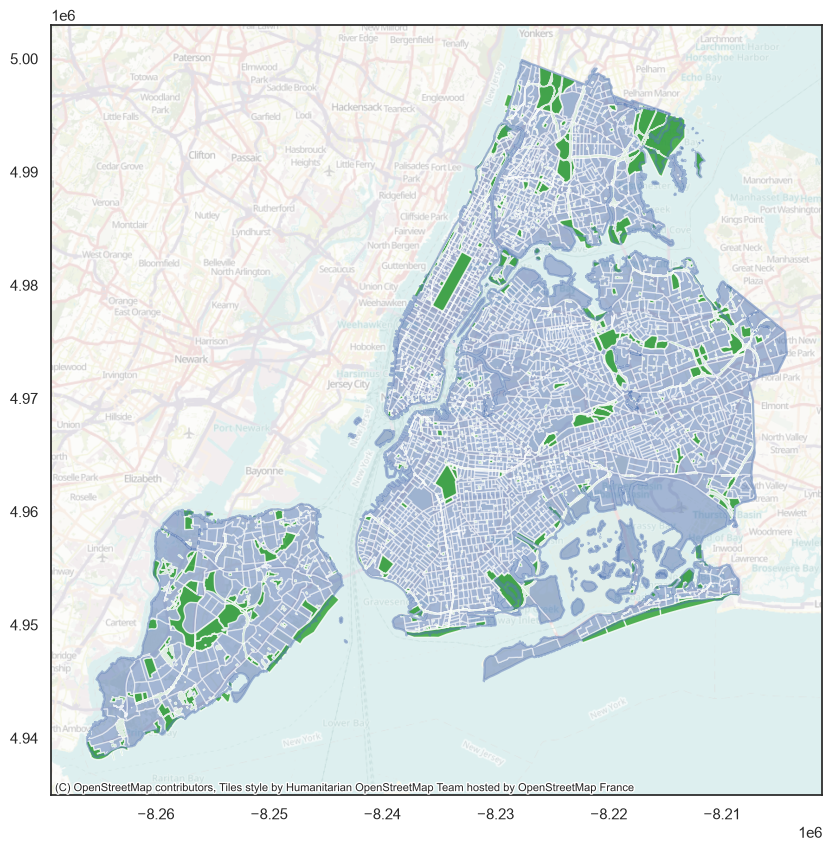

In [5]:
sns.set_theme(style="white")
# ax=nyc_census_tract.plot(column='Shape_Length', figsize=(10,10), alpha=0.8, cmap='inferno')
ax=nyc_boundary.boundary.plot(figsize=(10,10), alpha=0.5)
nyc_census_tract.plot(alpha=0.5, ax=ax)
nyc_park_properties.plot(alpha=0.8, color='tab:green', ax=ax)
cx.add_basemap(ax, crs=nyc_census_tract.crs, alpha=0.3)

ax.set_xlabel('')
ax.set_ylabel('')

## Calculate and plot park accessible area rate

In [10]:
park_union = nyc_park_properties.dissolve()
park_intersection = gpd.overlay(nyc_census_tract, park_union, how="intersection")

# we set 400m as buffer
nyc_park_properties["buffer"] = nyc_park_properties.geometry.buffer(400)
park_buffers = nyc_park_properties.set_geometry("buffer")
buffer_union = park_buffers.dissolve()
park_buffer_intersection = gpd.overlay(nyc_census_tract, buffer_union, how="intersection")

nyc_census_tract["total_area"] = nyc_census_tract.geometry.area
park_intersection["park_area"] = park_intersection.geometry.area
park_buffer_intersection['park_buffer_area'] = park_buffer_intersection.geometry.area

nyc_census_tract_merged = nyc_census_tract.merge(park_intersection[['GEOID', 'park_area']], on="GEOID", how="left").merge(park_buffer_intersection[['GEOID', 'park_buffer_area']], on="GEOID", how='left')

# Fill NaN (no coverage 0)
nyc_census_tract_merged[["park_area", 'park_buffer_area']]=nyc_census_tract_merged[["park_area", 'park_buffer_area']].fillna(0)
nyc_census_tract_merged["park_ratio"] = nyc_census_tract_merged["park_area"] / nyc_census_tract_merged["total_area"]
nyc_census_tract_merged["park_buffer_ratio"] = nyc_census_tract_merged["park_buffer_area"] / nyc_census_tract_merged["total_area"]
nyc_census_tract_merged = nyc_census_tract_merged.merge(race, on='GEOID', how='inner')

Text(0.5, 0.92, 'NYC park 400m buffer coverage per census tract')

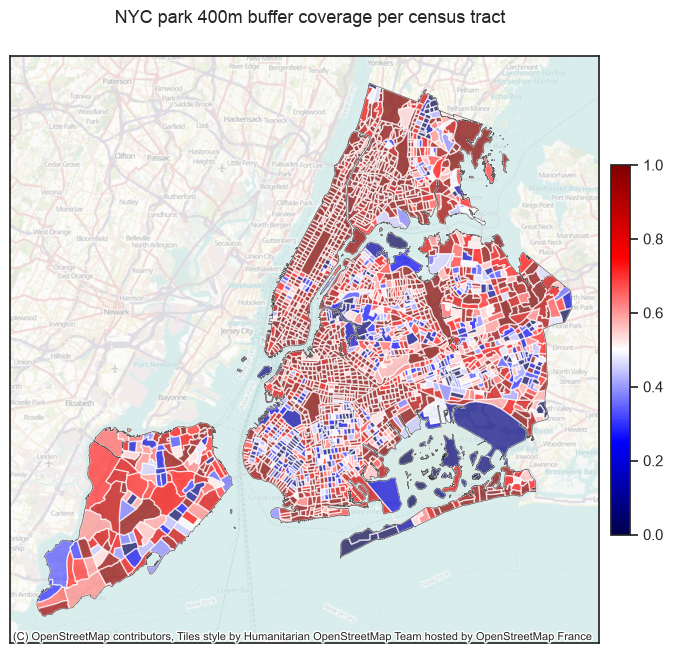

In [11]:
# plot the park BUFFER coverage ratio of census tract
ax=nyc_census_tract_merged.plot(
    column="park_buffer_ratio",
    cmap="seismic",
    legend=True, legend_kwds={
        "shrink": 0.6,       # 60% of original length
        "fraction": 0.03,    # thinner colorbar
        "pad": 0.02         # gap between map and colorbar
    },
    figsize=(8,8), alpha=0.7,
    edgecolor="white",
)
nyc_boundary.boundary.plot(alpha=0.6, linewidth=0.5, color='black',ax=ax)

cx.add_basemap(ax, crs=nyc_census_tract_merged.crs, alpha=0.35)
ax.set_xticklabels([])
ax.set_yticklabels([])
ax.set_xlabel('')
ax.set_ylabel('')

plt.suptitle('NYC park 400m buffer coverage per census tract', y=0.92, fontsize=13)

## Fit an OLS regression
Suppose our research question is:

_Is census tract population associated with the proportion of land covered by parks and their surrounding buffers in NYC?_

The OLS equation is:

${Park Buffer Ratio}_i=\beta_0+\beta_1\text{Population}_i+\epsilon_i$


In [12]:
# Ensure the data is a GeoDataFrame
gdf = nyc_census_tract_merged

# Remove missing values and invalid geometries
gdf = gdf.replace([np.inf, -np.inf], np.nan)
gdf = gdf.dropna(subset=["park_buffer_ratio", "thousand_population", "geometry"])
gdf = gdf[gdf.geometry.is_valid & ~gdf.geometry.is_empty]
gdf = gdf.reset_index(drop=True)

# Fit OLS regression
X = sm.add_constant(gdf[["thousand_population"]])
y = gdf["park_buffer_ratio"]

model = sm.OLS(y, X).fit()

print(model.summary())

# Save residuals
gdf["residuals"] = model.resid

                            OLS Regression Results                            
Dep. Variable:      park_buffer_ratio   R-squared:                       0.036
Model:                            OLS   Adj. R-squared:                  0.036
Method:                 Least Squares   F-statistic:                     87.41
Date:                Fri, 23 Oct 2026   Prob (F-statistic):           2.00e-20
Time:                        15:00:45   Log-Likelihood:                -580.63
No. Observations:                2325   AIC:                             1165.
Df Residuals:                    2323   BIC:                             1177.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                   0.6271    

## Map OLS residuals

When interpreting the map:
- Red tracts have higher park buffer coverage than predicted by population.
- Blue tracts have lower park buffer coverage than predicted.
- If neighboring tracts display similar residuals, this suggests spatial autocorrelation may remain.

Text(0.5, 0.92, 'Spatial Distribution of OLS Residuals')

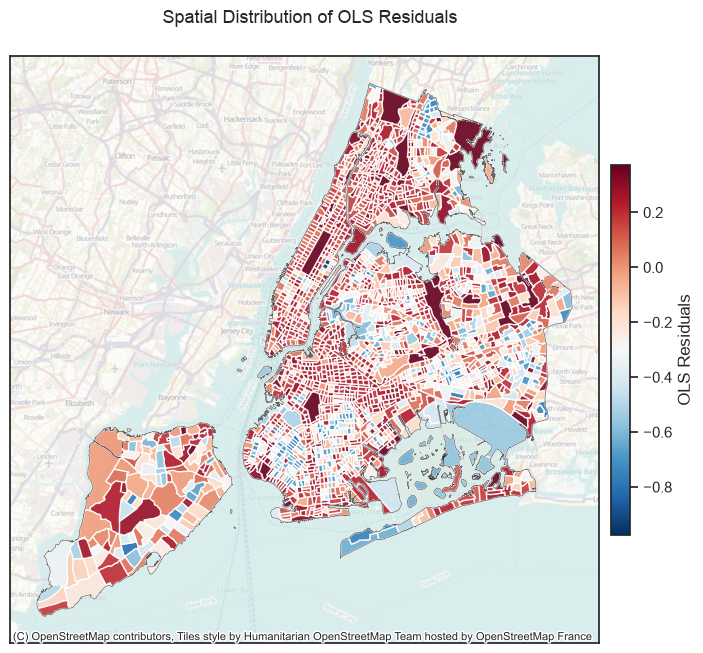

In [13]:

ax=gdf.plot(
    column="residuals",
    cmap="RdBu_r",
    legend=True, legend_kwds={"label": "OLS Residuals",
        "shrink": 0.6,       # 60% of original length
        "fraction": 0.03,    # thinner colorbar
        "pad": 0.02         # gap between map and colorbar
    },
    figsize=(8,8), alpha=0.9,
    edgecolor="white",
)
nyc_boundary.boundary.plot(alpha=0.6, linewidth=0.5, color='black',ax=ax)

cx.add_basemap(ax, crs=nyc_census_tract_merged.crs, alpha=0.35)
ax.set_xticklabels([])
ax.set_yticklabels([])
ax.set_xlabel('')
ax.set_ylabel('')

plt.suptitle('Spatial Distribution of OLS Residuals', y=0.92, fontsize=13)

## Calculate Global Moran's I
We first define spatial neighbors using Queen contiguity: two tracts are neighbors if they share at least one boundary point.

In [14]:
from libpysal.weights import Queen
from esda.moran import Moran
# Create spatial weights matrix
w = Queen.from_dataframe(gdf, use_index=False)
w.transform = "r"

print("Number of tracts:", len(gdf))
print("Number of tracts without neighbors:", len(w.islands))

('WARNING: ', 0, ' is an island (no neighbors)')
('WARNING: ', 1561, ' is an island (no neighbors)')
('WARNING: ', 1562, ' is an island (no neighbors)')
('WARNING: ', 1689, ' is an island (no neighbors)')
('WARNING: ', 1690, ' is an island (no neighbors)')
Number of tracts: 2325
Number of tracts without neighbors: 5


In [15]:
# Calculate Moran's I for three variables
variables = [
    "park_buffer_ratio",
    "population_for_sex_and_age",
    "residuals"
]

results = []

for var in variables:
    mi = Moran(gdf[var].to_numpy(), w, permutations=999)

    results.append({
        "Variable": var,
        "Moran's I": mi.I,
        "p-value": mi.p_sim
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))

                     Variable  Moran's I  p-value
0           park_buffer_ratio     0.4782    0.001
1  population_for_sex_and_age     0.3049    0.001
2                   residuals     0.4366    0.001


## Interpretation

Variable	Moran's I	p-value	Interpretation
park_buffer_ratio	0.4782	0.001	Substantial positive spatial clustering
population_for_sex_and_age	0.3049	0.001	Positive spatial clustering
residuals	0.4366	0.001	Substantial unexplained spatial clustering


Global Moran's I indicates significant positive spatial autocorrelation in park buffer coverage (I = 0.4782, p = 0.001) and census tract population (I = 0.3049, p = 0.001), suggesting that neighboring census tracts tend to exhibit similar values. More importantly, the OLS regression residuals also show significant positive spatial autocorrelation (I = 0.4366, p = 0.001). This suggests that population alone does not adequately explain the spatial distribution of park buffer coverage. Further investigation of omitted spatially structured variables or the use of spatial regression models may be warranted.

# Spatial regression
## Spatial model selection


In [16]:
import numpy as np
import spreg

# Define dependent and independent variables
y = gdf[["park_buffer_ratio"]].to_numpy()
X = gdf[["thousand_population"]].to_numpy()

# Fit OLS with spatial diagnostics
ols = spreg.OLS(
    y, X,
    w=w,
    spat_diag=True,
    moran=True,
    name_y="Park Buffer Ratio",
    name_x=["Population"]
)

print(ols.summary)

REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: ORDINARY LEAST SQUARES
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :     unknown
Dependent Variable  :Park Buffer Ratio                Number of Observations:        2325
Mean dependent var  :      0.7360                Number of Variables   :           2
S.D. dependent var  :      0.3165                Degrees of Freedom    :        2323
R-squared           :      0.0363
Adjusted R-squared  :      0.0358
Sum squared residual:     224.319                F-statistic           :     87.4109
Sigma-square        :       0.097                Prob(F-statistic)     :   2.003e-20
S.E. of regression  :       0.311                Log likelihood        :    -580.634
Sigma-square ML     :       0.096                Akaike info criterion :    1165.269
S.E of regression ML:      0.3106                Schwarz criterion     :    1176.772

------------

## Estimate both SAM and SDM model


In [17]:
import spreg

y = gdf[["park_buffer_ratio"]].to_numpy()
X = gdf[["thousand_population"]].to_numpy()

# Spatial Lag Model (SAR)
sar = spreg.ML_Lag(
    y, X, w=w,
    method="LU",
    slx_lags=0,
    name_y="Park Buffer Ratio",
    name_x=["Population"]
)

# Spatial Durbin Model (SDM)
sdm = spreg.ML_Lag(
    y, X, w=w,
    method="LU",
    slx_lags=1,
    name_y="Park Buffer Ratio",
    name_x=["Population"]
)

print(sar.summary)
print(sdm.summary)

ML_Lag
ML_Lag
REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = LU)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :     unknown
Dependent Variable  :Park Buffer Ratio                Number of Observations:        2325
Mean dependent var  :      0.7360                Number of Variables   :           3
S.D. dependent var  :      0.3165                Degrees of Freedom    :        2322
Pseudo R-squared    :      0.4829
Spatial Pseudo R-squared:  0.0811
Log likelihood      :    -63.0109
Sigma-square ML     :      0.0546                Akaike info criterion :     132.022
S.E of regression   :      0.2337                Schwarz criterion     :     149.276

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
---------------------------

In [18]:
print("SAR AIC:", sar.aic)
print("SDM AIC:", sdm.aic)

SAR AIC: 132.02170173370814
SDM AIC: 125.80547811238284


The results suggest that the Spatial Durbin Model (SDM) fits your data better than the Spatial Lag Model (SAR), after accounting for model complexity.

### Interpret the SDM result

Our estimated model is:
$y=\rho Wy+\beta X+\theta WX+\epsilon$

Where:
- \($y$\) = Park Buffer Ratio
- \($X$\) = Population (thousand)
- \($Wy$\) = Spatially weighted park buffer ratios of neighboring tracts
- \($WX$\) = Spatially weighted population of neighboring tracts
- \($\rho\$) = Spatial autoregressive coefficient

Interpretation:
- Population	0.00432	0.1172	Local population coefficient is not statistically significant
- W_Population	0.01300	0.0034	Neighboring population coefficient is positive and significant
- W_Park Buffer Ratio	0.72209	<0.001	Strong positive spatial dependence in park buffer coverage

